# Stage 1 - Fine-tune ViT5-base trên VietNews

Mục tiêu: huấn luyện model học **task summarization tiếng Việt** làm bệ phóng cho Stage 2 (domain y tế VnExpress).

Cấu hình chính (đồng bộ với file `stage1_bartpho_word.ipynb` để so sánh công bằng):
- Backbone: `VietAI/vit5-base`
- Dữ liệu: `nam194/vietnews`, lấy ~30k mẫu train có length ratio gần với domain đích (0.15-0.30)
- 3 epoch, bf16, batch 16, beam=1 khi eval (greedy) cho nhanh
- Đánh giá Stage 1 trên 2,000 mẫu test (cùng filter, cùng seed với file BARTpho để so sánh fair)

Chọn 30k vì:
- ViT5-base checkpoint gốc là pretrained span-corruption, chưa từng thấy summarization → cần đủ data để internalize task
- Stage 2 nhỏ (780 raw / 2.3k augmented) → không thể vừa học task vừa học domain
- 30k là sweet spot literature cho intermediate fine-tuning, ratio S1:S2 ~13× với augmented data
- Dưới 20k thường task chưa "chín"; trên 50k bắt đầu soak source style

In [1]:
# =========================
# VERIFY INSTALLATION
# =========================
import torch, transformers, datasets, evaluate, accelerate, fsspec

print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("evaluate:", evaluate.__version__)
print("accelerate:", accelerate.__version__)
print("fsspec:", fsspec.__version__)

torch: 2.5.1+cu121
transformers: 4.46.3
datasets: 3.1.0
evaluate: 0.4.3
accelerate: 1.1.1
fsspec: 2024.9.0


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import json
import time
import random
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import evaluate

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
)
from tqdm.auto import tqdm

In [4]:
# Tập trung mọi đường dẫn ở một nơi để dễ sửa
BASE_DIR    = "/content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/ViT5_stage_1"
DATA_DIR    = f"{BASE_DIR}/data/vietnews"
MODEL_DIR   = f"{BASE_DIR}/models/stage1_vit5"
FINAL_DIR   = f"{MODEL_DIR}/final_model"
METRICS_DIR = f"{BASE_DIR}/metrics/plots"
EVAL_DIR    = f"{BASE_DIR}/metrics/test_eval"

for d in (DATA_DIR, MODEL_DIR, METRICS_DIR, EVAL_DIR):
    os.makedirs(d, exist_ok=True)

MODEL_CHECKPOINT = "VietAI/vit5-base"
MAX_INPUT_LEN    = 1024
MAX_TARGET_LEN   = 256
SEED             = 42

TRAIN_SIZE = 20000
VAL_SIZE   = 2000
TEST_SIZE  = 2000

# Generate config dùng chung cho test - giữ y hệt giữa BARTpho và ViT5 để fair
GEN_MAX_LEN   = 160
GEN_NUM_BEAMS = 4
GEN_BATCH     = 8

# 1. Tải và xử lý dữ liệu

Stage 2 dùng domain y tế VnExpress với length ratio 0.20-0.25 và độ dài bài 250-2500 từ. Để giảm shock giữa hai stage, ta lọc VietNews giữ các mẫu có đặc tính gần tương tự (nới lỏng nhẹ ratio xuống 0.15-0.30) trước khi lấy mẫu. Filter này áp cho cả train/val/test và **giữ y nguyên** như file BARTpho để hai model học cùng phân phối.

In [ ]:
print("Đang tải bộ dữ liệu VietNews...")
dataset = load_dataset("nam194/vietnews")
print(dataset)

In [ ]:
# Filter theo độ dài và length ratio để gần với domain đích (Stage 2)
def keep_close_to_target(example):
    src_words = len(example["article"].split())
    tgt_words = len(example["abstract"].split())
    if src_words < 100 or src_words > 1500:
        return False
    if tgt_words < 15 or tgt_words > 150:
        return False
    ratio = tgt_words / src_words
    return 0.05 <= ratio <= 0.45

filtered_train = dataset["train"].filter(keep_close_to_target)
filtered_val   = dataset["validation"].filter(keep_close_to_target)
filtered_test  = dataset["test"].filter(keep_close_to_target)
print(f"Train sau filter: {len(filtered_train):,} | Val: {len(filtered_val):,} | Test: {len(filtered_test):,}")

train_dataset = filtered_train.shuffle(seed=SEED).select(range(min(TRAIN_SIZE, len(filtered_train))))
val_dataset   = filtered_val.shuffle(seed=SEED).select(range(min(VAL_SIZE, len(filtered_val))))
test_dataset  = filtered_test.shuffle(seed=SEED).select(range(min(TEST_SIZE, len(filtered_test))))
print(f"Train dùng: {len(train_dataset):,} | Val dùng: {len(val_dataset):,} | Test dùng: {len(test_dataset):,}")

In [8]:
# Xuất dữ liệu thô ra JSONL để dễ kiểm tra / tái lập
train_dataset.to_json(f"{DATA_DIR}/train_{len(train_dataset)}.jsonl", force_ascii=False)
val_dataset.to_json(f"{DATA_DIR}/val_{len(val_dataset)}.jsonl", force_ascii=False)
test_dataset.to_json(f"{DATA_DIR}/test_{len(test_dataset)}.jsonl", force_ascii=False)
print(f"Đã lưu dữ liệu thô tại: {DATA_DIR}")

Creating json from Arrow format:   0%|          | 0/20 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Đã lưu dữ liệu thô tại: /content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/ViT5_stage_1/data/vietnews


In [9]:
# ViT5 dùng SentencePiece, AutoTokenizer trả về T5TokenizerFast mặc định
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT, use_fast=False)
print(f"Tokenizer: {type(tokenizer).__name__} | vocab_size={tokenizer.vocab_size}")

def preprocess_function(examples):
    model_inputs = tokenizer(
        examples["article"],
        max_length=MAX_INPUT_LEN,
        truncation=True,
    )
    labels = tokenizer(
        text_target=examples["abstract"],
        max_length=MAX_TARGET_LEN,
        truncation=True,
    )
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


Tokenizer: T5Tokenizer | vocab_size=36000


In [10]:
print("Đang tokenize dữ liệu...")
tokenized_train = train_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=train_dataset.column_names,
)
tokenized_val = val_dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=val_dataset.column_names,
)
print("Đã chuẩn bị xong dữ liệu huấn luyện.")

Đang tokenize dữ liệu...
Đã chuẩn bị xong dữ liệu huấn luyện.


# 2. Hàm đánh giá (ROUGE)

Tiếng Việt không dùng được Porter stemmer (vốn cho tiếng Anh) nên đặt `use_stemmer=False`. Ta cũng xử lý cả `-100` ở predictions phòng trường hợp generate bị pad.

In [ ]:
def rouge_tokenize(text):
    import re
    import unicodedata
    return re.findall(r"[^\W_]+", unicodedata.normalize("NFC", str(text)).casefold())


rouge = evaluate.load("rouge")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.where(predictions != -100, predictions, tokenizer.pad_token_id)
    labels      = np.where(labels      != -100, labels,      tokenizer.pad_token_id)

    decoded_preds  = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels,      skip_special_tokens=True)

    decoded_preds  = ["\n".join(p.strip().split()) for p in decoded_preds]
    decoded_labels = ["\n".join(l.strip().split()) for l in decoded_labels]

    result = rouge.compute(tokenizer=rouge_tokenize, rouge_types=["rouge1", "rouge2", "rougeL"], 
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=False,
    )
    return {k: round(v * 100, 4) for k, v in result.items()}

print("Đã cài đặt hàm đánh giá ROUGE.")

# 3. Training

Cấu hình **giữ y hệt** file BARTpho để so sánh công bằng:
- `bf16=True` cho A100 (đổi sang `fp16=True` nếu chạy trên T4/L4 — lưu ý T5 family hay bị NaN với fp16, nếu gặp NaN hãy giảm LR hoặc bật `tf32`)
- `batch=16` x `grad_accum=2` => effective batch = 32
- `num_train_epochs=3` đủ cho intermediate fine-tuning, tránh overfit vào VietNews
- Eval với `num_beams=1` (greedy) cho nhanh; sẽ chạy beam search ở cell test cuối

In [14]:
print("Đang nạp mô hình ViT5-base...")
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_CHECKPOINT)
data_collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)

training_args = Seq2SeqTrainingArguments(
    output_dir=MODEL_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=16, # Giữ nguyên 16 nếu bật checkpointing
    per_device_eval_batch_size=8,   # GIẢM XUỐNG để tránh OOM lúc Eval
    gradient_accumulation_steps=2,

    gradient_checkpointing=True,    # BẮT BUỘC bật cái này

    weight_decay=0.01,
    warmup_ratio=0.05,
    num_train_epochs=3,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    predict_with_generate=True,     # Giữ nguyên nhưng Eval batch phải nhỏ
    generation_max_length=160,
    generation_num_beams=1,
    bf16=True,
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

Đang nạp mô hình ViT5-base...


In [16]:
print("Bắt đầu huấn luyện Stage 1...")
trainer.train()

trainer.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
print(f"Huấn luyện hoàn tất. Model tốt nhất đã lưu tại: {FINAL_DIR}")

Bắt đầu huấn luyện Stage 1...


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,1.519000,1.358449,57.047400,26.053700,36.807000,56.859400
2,1.382500,1.315893,57.897200,27.261200,37.711500,57.730100
3,1.284100,1.307238,58.311100,27.291600,37.769100,58.130500


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


Huấn luyện hoàn tất. Model tốt nhất đã lưu tại: /content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/ViT5_stage_1/models/stage1_vit5/final_model


# 4. Biểu đồ loss

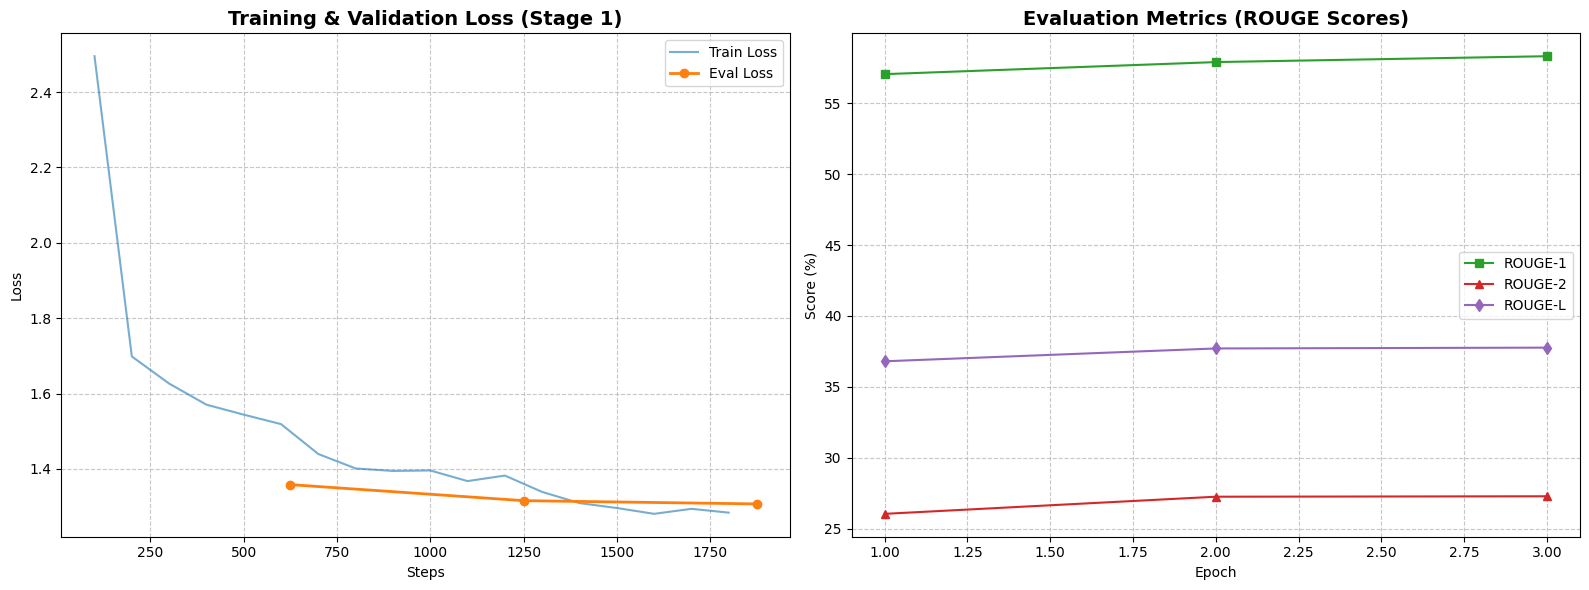

Biểu đồ đã được lưu tại: /content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/ViT5_stage_1/metrics/plots/stage1_final_metrics.png


In [5]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd

# 1. Cấu hình đường dẫn - Hãy đảm bảo đường dẫn này chính xác
# Lưu ý: Thường trainer_state.json nằm trong thư mục checkpoint cuối cùng
BASE_PATH = "/content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/ViT5_stage_1"
CHECKPOINT_DIR = f"{BASE_PATH}/models/stage1_vit5/checkpoint-1875"
METRICS_DIR = f"{BASE_PATH}/metrics/plots"
STATE_FILE = os.path.join(CHECKPOINT_DIR, "trainer_state.json")

# Tạo thư mục lưu plot nếu chưa có
os.makedirs(METRICS_DIR, exist_ok=True)

# 2. Đọc dữ liệu từ file JSON
if not os.path.exists(STATE_FILE):
    print(f"Lỗi: Không tìm thấy file tại {STATE_FILE}")
else:
    with open(STATE_FILE, "r") as f:
        state = json.load(f)

    log_history = state["log_history"]

    # 3. Phân tách dữ liệu Train và Eval
    train_logs = [entry for entry in log_history if "loss" in entry and "step" in entry and "eval_loss" not in entry]
    eval_logs = [entry for entry in log_history if "eval_loss" in entry]

    # Chuyển sang DataFrame để dễ xử lý
    df_train = pd.DataFrame(train_logs)
    df_eval = pd.DataFrame(eval_logs)

    # 4. Vẽ biểu đồ
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # --- Đồ thị Loss (Train vs Eval) ---
    axes[0].plot(df_train["step"], df_train["loss"], label="Train Loss", color="#1f77b4", alpha=0.6)
    if not df_eval.empty:
        # Do eval tính theo epoch, ta cần map epoch sang step tương ứng để vẽ cùng trục hoặc vẽ theo epoch
        # Ở đây vẽ theo Step để so sánh tương quan
        axes[0].plot(df_eval["step"], df_eval["eval_loss"], label="Eval Loss", color="#ff7f0e", marker="o", linewidth=2)

    axes[0].set_title("Training & Validation Loss (Stage 1)", fontsize=14, fontweight='bold')
    axes[0].set_xlabel("Steps")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.7)

    # --- Đồ thị ROUGE Scores ---
    if not df_eval.empty and "eval_rouge1" in df_eval.columns:
        axes[1].plot(df_eval["epoch"], df_eval["eval_rouge1"], label="ROUGE-1", marker="s", color="#2ca02c")
        axes[1].plot(df_eval["epoch"], df_eval["eval_rouge2"], label="ROUGE-2", marker="^", color="#d62728")
        axes[1].plot(df_eval["epoch"], df_eval["eval_rougeL"], label="ROUGE-L", marker="d", color="#9467bd")

        axes[1].set_title("Evaluation Metrics (ROUGE Scores)", fontsize=14, fontweight='bold')
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Score (%)")
        axes[1].legend()
        axes[1].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()

    # 5. Lưu biểu đồ
    save_path = os.path.join(METRICS_DIR, "stage1_final_metrics.png")
    plt.savefig(save_path, dpi=150)
    plt.show()

    print(f"Biểu đồ đã được lưu tại: {save_path}")

# 5. Đánh giá trên tập test

Generate trên `test_dataset` (2,000 mẫu, cùng filter & seed với file BARTpho) bằng beam search 4. Tính ROUGE-1/2/L và lưu predictions ra JSONL để đối chiếu định tính với model còn lại.

In [8]:
import torch
import time
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# --- CẤU HÌNH ĐƯỜNG DẪN (Dựa trên ảnh của bạn) ---
BASE_DIR = "/content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/ViT5_stage_1"
FINAL_DIR = f"{BASE_DIR}/models/stage1_vit5/final_model"
TEST_FILE = f"{BASE_DIR}/data/vietnews/test_2000.jsonl"

# --- THÔNG SỐ GENERATE ---
GEN_BATCH = 16
MAX_INPUT_LEN = 1024
GEN_MAX_LEN = 160
GEN_NUM_BEAMS = 1 # Để là 1 cho nhanh, hoặc 4 nếu muốn chất lượng cao hơn
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# 1. Load tập dataset test (Sửa lỗi NameError)
print("Đang nạp tập dữ liệu test...")
test_dataset = load_dataset("json", data_files=TEST_FILE, split="train")

# 2. Load Model và Tokenizer
print(f"Đang nạp mô hình từ: {FINAL_DIR}")
eval_tokenizer = AutoTokenizer.from_pretrained(FINAL_DIR, use_fast=False)
eval_model = AutoModelForSeq2SeqLM.from_pretrained(FINAL_DIR).to(DEVICE)
eval_model.eval()
preds, refs = [], []
start = time.time()

print("Bắt đầu quá trình tóm tắt trên tập Test...")
with torch.no_grad():
    for i in tqdm(range(0, len(test_dataset), GEN_BATCH), desc="Generate test"):
        # Lấy một batch mẫu
        batch = test_dataset[i:i + GEN_BATCH]

        # Tokenize đầu vào
        inputs = eval_tokenizer(
            batch["article"],
            max_length=MAX_INPUT_LEN,
            truncation=True,
            padding=True,
            return_tensors="pt",
        ).to(DEVICE)

        # Sinh văn bản (Inference)
        out = eval_model.generate(
            **inputs,
            max_length=GEN_MAX_LEN,
            num_beams=GEN_NUM_BEAMS,
            no_repeat_ngram_size=3,
            early_stopping=True,
        )

        # Giải mã kết quả
        decoded = eval_tokenizer.batch_decode(out, skip_special_tokens=True)
        preds.extend(decoded)
        refs.extend(batch["abstract"])

elapsed = time.time() - start
print(f"\nGenerate xong {len(preds)} mẫu trong {elapsed:.1f}s ({elapsed/len(preds)*1000:.1f} ms/mẫu)")

Đang nạp tập dữ liệu test...


Generating train split: 0 examples [00:00, ? examples/s]

Đang nạp mô hình từ: /content/drive/MyDrive/C.Science - TDTU/NLP/Finalterm NLP/ViT5_stage_1/models/stage1_vit5/final_model
Bắt đầu quá trình tóm tắt trên tập Test...


Generate test:   0%|          | 0/125 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/generation/configuration_utils.py:638: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `early_stopping`.
  warnings.warn(



Generate xong 2000 mẫu trong 306.4s (153.2 ms/mẫu)


In [ ]:
def rouge_tokenize(text):
    import re
    import unicodedata
    return re.findall(r"[^\W_]+", unicodedata.normalize("NFC", str(text)).casefold())


import evaluate
rouge = evaluate.load("rouge")
results = rouge.compute(tokenizer=rouge_tokenize, rouge_types=["rouge1", "rouge2", "rougeL"], predictions=preds, references=refs)
print("Kết quả ROUGE trên tập Test:", results)

In [ ]:
def rouge_tokenize(text):
    import re
    import unicodedata
    return re.findall(r"[^\W_]+", unicodedata.normalize("NFC", str(text)).casefold())


import json
import random
import pandas as pd
import torch
import evaluate

# Đảm bảo EVAL_DIR đã được khởi tạo
os.makedirs(EVAL_DIR, exist_ok=True)

def normalize(text):
    """
    Chuẩn hóa văn bản bằng cách loại bỏ khoảng trắng thừa
    và đưa về dạng một từ mỗi dòng (giúp ROUGE tính toán chính xác hơn).
    """
    return "\n".join(text.strip().split())

# 1. Tính toán ROUGE Score
print("Đang tính toán ROUGE Metrics...")
rouge = evaluate.load("rouge")

test_result = rouge.compute(tokenizer=rouge_tokenize, rouge_types=["rouge1", "rouge2", "rougeL"], 
    predictions=[normalize(p) for p in preds],
    references=[normalize(r) for r in refs],
    use_stemmer=False,
)

# 2. Định dạng lại kết quả
test_result = {k: round(v * 100, 4) for k, v in test_result.items()}
test_result["latency_ms_per_sample"] = round(elapsed / len(preds) * 1000, 2)
test_result["n_samples"] = len(preds)
test_result["model"] = "ViT5-base (Stage 1)"

# 3. Hiển thị bảng kết quả
df = pd.DataFrame([test_result])
print("\n" + "="*30 + " TEST METRICS " + "="*30)
print(df.to_string(index=False))

# 4. Lưu kết quả Metrics (JSON & CSV)
with open(f"{EVAL_DIR}/stage1_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(test_result, f, ensure_ascii=False, indent=2)
df.to_csv(f"{EVAL_DIR}/stage1_test_metrics.csv", index=False)
print(f"\n[Hệ thống] Đã lưu metrics tại: {EVAL_DIR}")

# 5. Lưu chi tiết dự đoán (JSONL) để phân tích sau này
preds_path = f"{EVAL_DIR}/stage1_test_predictions.jsonl"
with open(preds_path, "w", encoding="utf-8") as f:
    for i in range(len(test_dataset)):
        row = {
            "guid": test_dataset[i].get("guid"),
            "article": test_dataset[i]["article"],
            "reference": test_dataset[i]["abstract"],
            "prediction": preds[i],
        }
        f.write(json.dumps(row, ensure_ascii=False) + "\n")
print(f"[Hệ thống] Đã lưu {len(preds)} predictions tại: {preds_path}")

# 6. Xem nhanh 3 ví dụ ngẫu nhiên để cảm nhận chất lượng
random.seed(SEED)
print("\n" + "="*30 + " QUALITATIVE ANALYSIS " + "="*30)
for idx in random.sample(range(len(test_dataset)), 3):
    print(f"\n[Sample {idx}]")
    print(f"Ref: {test_dataset[idx]['abstract']}")
    print(f"Gen: {preds[idx]}")
    print("-" * 40)